<a href="https://colab.research.google.com/github/Tanuja-code125/Applied-ML-Lab/blob/main/ML_Exp8.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

#Implement a classification model to distinguish between normal and abnormal
physiological signals using extracted signal features. (perform comparative analysis on different ML models)


In [ ]:
import pandas as pd
import numpy as np
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier
from sklearn.ensemble import RandomForestClassifier
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import accuracy_score, ConfusionMatrixDisplay

In [ ]:
# Step 2: Read dataset
df = pd.read_csv("/content/mitbih_test.csv.zip")

In [ ]:
# Step 3: Separate signals and labels
X = df.iloc[:, :-1].values
y = (df.iloc[:, -1].values != 0).astype(int)

In [ ]:
# Step 4: Extract features
X = np.column_stack([
    np.mean(X, axis=1),
    np.std(X, axis=1),
    np.max(X, axis=1),
    np.min(X, axis=1)
])

In [ ]:
# Step 5: Split data into training and testing
# Drop any rows with NaN values that might cause split or training errors
valid_mask = ~np.isnan(X).any(axis=1)
X_clean = X[valid_mask]
y_clean = y[valid_mask]

# Split using the cleaned non-NaN dataset
X_train, X_test, y_train, y_test = train_test_split(
    X_clean, y_clean, test_size=0.2, random_state=42, stratify=y_clean
)

In [ ]:
# Step 6: Compare ML models
models = {
    "Logistic Regression": LogisticRegression(max_iter=1000),
    "Decision Tree": DecisionTreeClassifier(random_state=42),
    "Random Forest": RandomForestClassifier(
        n_estimators=100, random_state=42
    )
}

for name, model in models.items():
    model.fit(X_train, y_train)
    prediction = model.predict(X_test)

    print(name, "Accuracy:",
          round(accuracy_score(y_test, prediction) * 100, 2), "%")

Logistic Regression Accuracy: 81.64 %
Decision Tree Accuracy: 80.91 %
Random Forest Accuracy: 85.16 %


In [ ]:
# Step 7: Train the final model
model = RandomForestClassifier(n_estimators=100, random_state=42)
model.fit(X_train, y_train)
prediction = model.predict(X_test)

print("\nRandom Forest Accuracy:",
      round(accuracy_score(y_test, prediction) * 100, 2), "%")


Random Forest Accuracy: 85.16 %


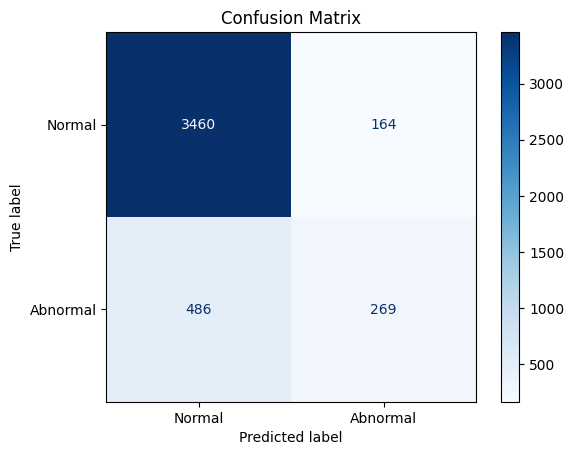

Experiment completed successfully!


In [ ]:
import matplotlib.pyplot as plt

# Step 8: Display confusion matrix
ConfusionMatrixDisplay.from_predictions(
    y_test,
    prediction,
    display_labels=["Normal", "Abnormal"],
    cmap="Blues"
)

plt.title("Confusion Matrix")
plt.show()

print("Experiment completed successfully!")